In [1]:
import torch
import clip
from medmnist import PathMNIST, INFO
import torchvision.transforms as transforms

# Set device (CPU or GPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cpu


In [17]:
# Load CLIP model
model_name = "ViT-B/32"
clip_model, clip_preprocess = clip.load(model_name, device=device, jit=False)
clip_model.eval()  # set to evaluation mode
print("CLIP model loaded:", model_name)


CLIP model loaded: ViT-B/32


Train samples: 89996
Validation samples: 10004
Test samples: 7180
Label index: [8]


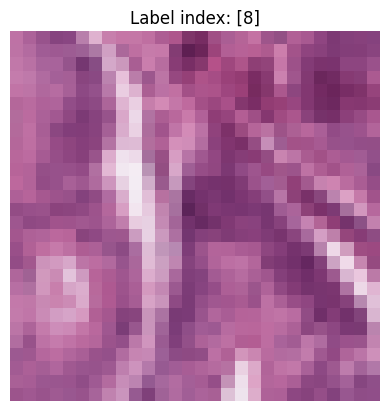

In [18]:
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torchvision.transforms import ToTensor

# Minimal transform: convert images to tensor
transform = ToTensor()

# Load PathMNIST splits (download=False because dataset is already downloaded)
train_ds = PathMNIST(split='train', transform=transform, download=False)
val_ds   = PathMNIST(split='val', transform=transform, download=False)
test_ds  = PathMNIST(split='test', transform=transform, download=False)

# Inspect number of samples
print("Train samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))

# Pick one image to visualize
img, label = test_ds[0]  # first test image
print("Label index:", label)

# Show image
plt.imshow(img.permute(1,2,0))  # convert from (C,H,W) -> (H,W,C)
plt.title(f"Label index: {label}")
plt.axis('off')
plt.show()


In [19]:
from PIL import Image
import torchvision.transforms.functional as TF

def tensor28_to_clip_input(tensor28):
    """
    Convert a PathMNIST 28x28 tensor to a CLIP-ready input.
    tensor28: torch.Tensor (C,H,W) with values in [0,1]
    Returns: torch.Tensor (1,3,224,224) on the correct device
    """
    # Convert to PIL image
    pil_img = TF.to_pil_image(tensor28)
    # Apply CLIP preprocessing (resize, center crop, normalize)
    clip_input = clip_preprocess(pil_img).unsqueeze(0).to(device)
    return clip_input

# Test on the first image
clip_input = tensor28_to_clip_input(img)
print("CLIP input shape:", clip_input.shape)  # should be (1,3,224,224)


CLIP input shape: torch.Size([1, 3, 224, 224])


In [20]:
# Create text prompts for all 9 classes
class_dict = INFO['pathmnist']['label']  # mapping index -> class name
num_classes = len(class_dict)

prompts = [f"a microscopy image of {class_dict[str(i)]}" for i in range(num_classes)]

# Tokenize prompts for CLIP
text_tokens = clip.tokenize(prompts).to(device)

# Encode image and text embeddings
with torch.no_grad():
    image_emb = clip_model.encode_image(clip_input)     # (1, D)
    text_emb  = clip_model.encode_text(text_tokens)     # (num_classes, D)
    # Normalize embeddings
    image_emb = image_emb / image_emb.norm(dim=-1, keepdim=True)
    text_emb  = text_emb / text_emb.norm(dim=-1, keepdim=True)
    # Compute cosine similarity
    sims = (image_emb @ text_emb.T).squeeze(0).cpu().numpy()

# Get top prediction
top_idx = sims.argmax()
true_label = int(label)  # convert tensor to int
print("True label:", class_dict[str(true_label)])
print("CLIP prediction:", class_dict[str(top_idx)])


True label: colorectal adenocarcinoma epithelium
CLIP prediction: cancer-associated stroma


C:\Users\Acer\AppData\Local\Temp\ipykernel_10744\466286922.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  true_label = int(label)  # convert tensor to int


In [21]:
import torch.nn.functional as F

def zero_shot_predict(images28_tensor, prompts_per_class):
    """
    images28_tensor: torch.Tensor (B, C, H, W) with values in [0,1]
    prompts_per_class: list of lists of prompt strings per class
                       e.g. [["a photo of Adipose"], ["a microscopy image of Muscle"], ...]
    Returns: list of predicted class indices
    """
    num_classes = len(prompts_per_class)
    # Compute averaged text embeddings per class
    all_class_embs = []
    with torch.no_grad():
        for prompt_list in prompts_per_class:
            tokens = clip.tokenize(prompt_list).to(device)  # (n_prompts, L)
            emb = clip_model.encode_text(tokens)           # (n_prompts, D)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            emb_mean = emb.mean(dim=0, keepdim=True)       # (1, D)
            emb_mean = emb_mean / emb_mean.norm(dim=-1, keepdim=True)
            all_class_embs.append(emb_mean)
        text_embs = torch.cat(all_class_embs, dim=0)      # (num_classes, D)

    # Process each image
    preds = []
    for i in range(images28_tensor.shape[0]):
        img_tensor = images28_tensor[i]
        clip_input = tensor28_to_clip_input(img_tensor)
        with torch.no_grad():
            image_emb = clip_model.encode_image(clip_input)
            image_emb = image_emb / image_emb.norm(dim=-1, keepdim=True)
            sims = (image_emb @ text_embs.T).squeeze(0).cpu().numpy()
            top_idx = sims.argmax()
            preds.append(int(top_idx))
    return preds


C:\Users\Acer\AppData\Local\Temp\ipykernel_10744\1208512164.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  true_labels = [int(test_ds[i][1]) for i in range(batch_size)]


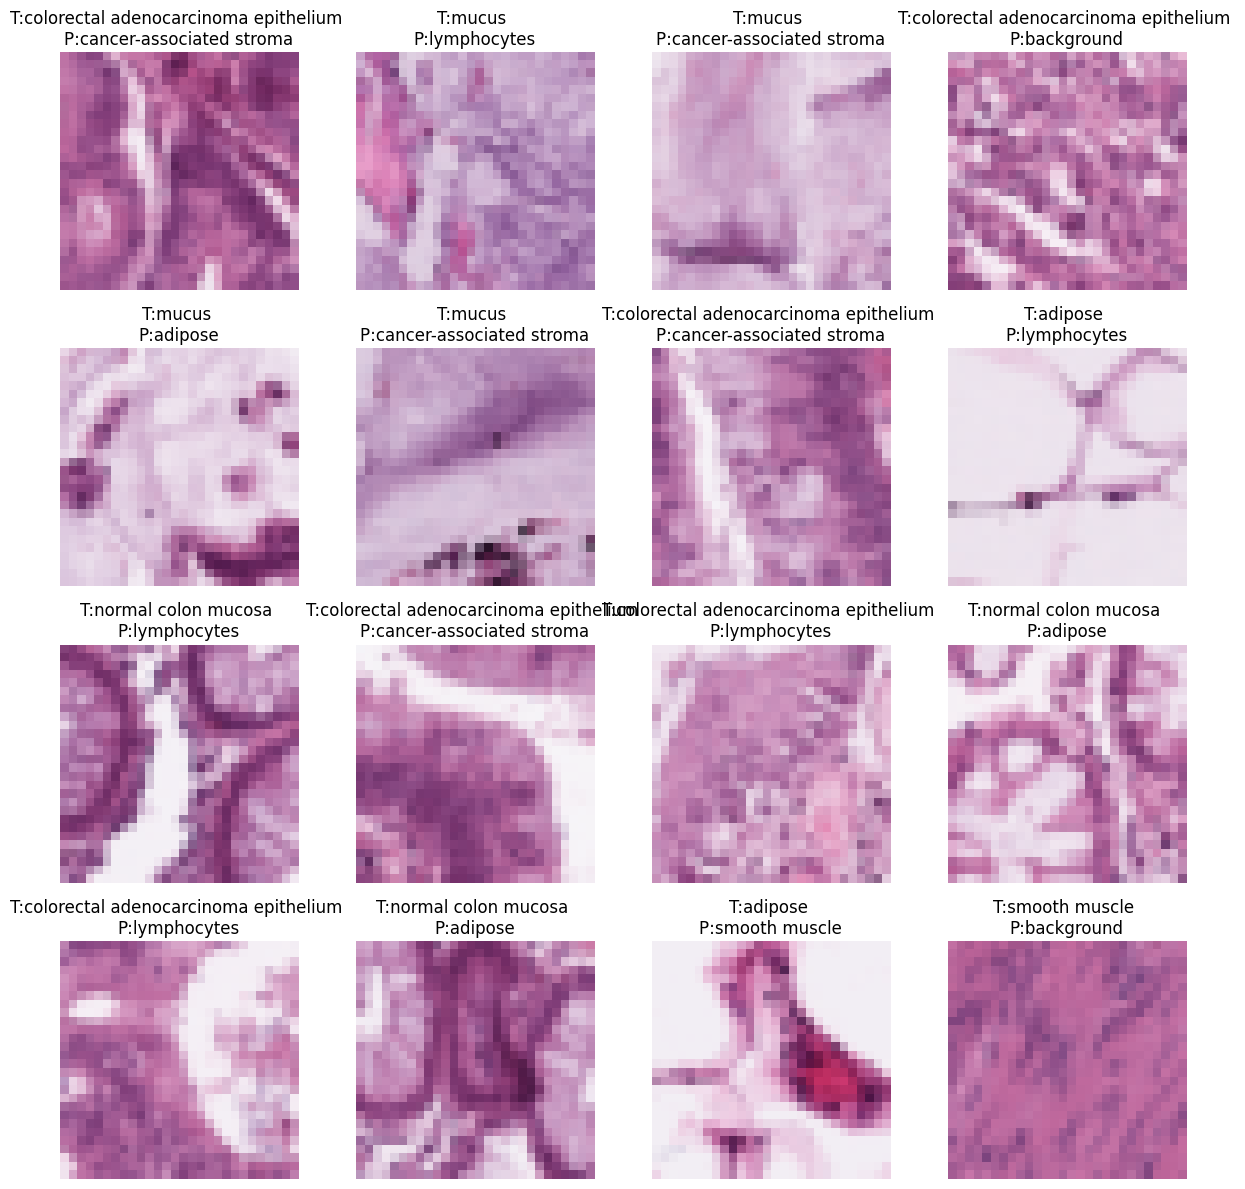

In [8]:
# Build a batch of first 16 test images
batch_size = 16
imgs = torch.stack([test_ds[i][0] for i in range(batch_size)])  # (16,C,H,W)
true_labels = [int(test_ds[i][1]) for i in range(batch_size)]

# Simple prompt: one prompt per class
prompts_per_class = [[f"a microscopy image of {class_dict[str(i)]}"] for i in range(num_classes)]

# Get predictions
preds = zero_shot_predict(imgs, prompts_per_class)

# Visualize results
import matplotlib.pyplot as plt

plt.figure(figsize=(12,12))
for i in range(batch_size):
    ax = plt.subplot(4,4,i+1)
    img = imgs[i].permute(1,2,0)  # (C,H,W) -> (H,W,C)
    plt.imshow(img)
    plt.title(f"T:{class_dict[str(true_labels[i])]} \nP:{class_dict[str(preds[i])]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


In [22]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm.notebook import tqdm

# Prepare all test images and labels
all_images = torch.stack([test_ds[i][0] for i in range(len(test_ds))])
all_labels = [int(test_ds[i][1]) for i in range(len(test_ds))]

# Use the same domain prompt (one prompt per class)
prompts_per_class = [[f"a microscopy image of {class_dict[str(i)]}"] for i in range(num_classes)]

# Predict in batches to avoid memory issues
batch_size = 100  # adjust if needed
all_preds = []

for i in tqdm(range(0, len(all_images), batch_size)):
    batch_imgs = all_images[i:i+batch_size]
    batch_preds = zero_shot_predict(batch_imgs, prompts_per_class)
    all_preds.extend(batch_preds)

# Compute metrics
acc = accuracy_score(all_labels, all_preds)
print(f"Zero-shot accuracy on full test set: {acc*100:.2f}%\n")

# Per-class report
print("Classification report:")
print(classification_report(all_labels, all_preds, target_names=[class_dict[str(i)] for i in range(num_classes)], zero_division=0))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
print("Confusion matrix:\n", cm)


C:\Users\Acer\AppData\Local\Temp\ipykernel_10744\3493094943.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  all_labels = [int(test_ds[i][1]) for i in range(len(test_ds))]


  0%|          | 0/72 [00:00<?, ?it/s]

Zero-shot accuracy on full test set: 12.16%

Classification report:
                                      precision    recall  f1-score   support

                             adipose       0.59      0.29      0.39      1338
                          background       0.04      0.09      0.06       847
                              debris       0.00      0.00      0.00       339
                         lymphocytes       0.09      0.45      0.15       634
                               mucus       0.00      0.00      0.00      1035
                       smooth muscle       0.13      0.14      0.13       592
                 normal colon mucosa       0.80      0.01      0.01       741
            cancer-associated stroma       0.04      0.08      0.05       421
colorectal adenocarcinoma epithelium       0.30      0.01      0.02      1233

                            accuracy                           0.12      7180
                           macro avg       0.22      0.12      0.09     

In [29]:
import pickle

# Save predictions and true labels
with open("zero_shot_preds.pkl", "wb") as f:
    pickle.dump({"preds": all_preds, "true_labels": all_labels}, f)

print("Zero-shot predictions saved!")


Zero-shot predictions saved!


In [30]:
import torch.nn as nn

# Example: linear probe
class LinearProbe(nn.Module):
    def __init__(self, clip_model, num_classes):
        super().__init__()
        self.clip_model = clip_model
        for param in self.clip_model.parameters():  # freeze CLIP
            param.requires_grad = False
        self.linear = nn.Linear(512, num_classes)  # ViT-B/32 has 512-dim embeddings

    def forward(self, x):
        with torch.no_grad():
            emb = self.clip_model.encode_image(x)
        emb = emb / emb.norm(dim=-1, keepdim=True)
        return self.linear(emb)


In [31]:
# Number of classes in PathMNIST
num_classes = len(class_dict)

# Create the linear probe model
linear_probe = LinearProbe(clip_model, num_classes)

# Move to device
linear_probe = linear_probe.to(device)

print("Linear probe model created and ready for training.")


Linear probe model created and ready for training.


In [32]:
torch.save(linear_probe.state_dict(), "linear_probe_model.pth")
print("Linear probe model saved!")


Linear probe model saved!


In [33]:
from torch.utils.data import DataLoader, Dataset

# Custom dataset to apply CLIP preprocessing
class PathMNIST_CLIP(Dataset):
    def __init__(self, pathmnist_ds):
        self.ds = pathmnist_ds

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        img, label = self.ds[idx]
        # Convert 28x28 tensor -> CLIP input
        clip_input = tensor28_to_clip_input(img).squeeze(0)  # remove batch dim
        return clip_input, label

# Create datasets
train_clip_ds = PathMNIST_CLIP(train_ds)
val_clip_ds   = PathMNIST_CLIP(val_ds)

# Create dataloaders
batch_size = 64  # adjust if CPU is slow
train_loader = DataLoader(train_clip_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_clip_ds, batch_size=batch_size)


In [34]:
import torch
from tqdm.notebook import tqdm

# Make sure linear_probe.clip_model is on device
linear_probe.eval()  # encoder is frozen

# Choose train or val
datasets = {"train": train_ds, "val": val_ds}
embeddings = {}
labels_dict = {}

for split, ds in datasets.items():
    all_embs = []
    all_labels = []
    for img, label in tqdm(ds, desc=f"Caching {split} embeddings"):
        # Convert 28x28 tensor -> CLIP input
        clip_input = tensor28_to_clip_input(img)  # shape: (1,3,224,224)
        with torch.no_grad():
            emb = linear_probe.clip_model.encode_image(clip_input.to(device))
            emb = emb / emb.norm(dim=-1, keepdim=True)  # normalize
        all_embs.append(emb.cpu())
        all_labels.append(torch.tensor(label))
    embeddings[split] = torch.cat(all_embs, dim=0)  # shape: (N, 512)
    labels_dict[split] = torch.stack(all_labels)

# Save cached embeddings for future use
torch.save({"embeddings": embeddings, "labels": labels_dict}, "cached_clip_embeddings.pth")
print("Embeddings cached successfully!")


Caching train embeddings:   0%|          | 0/89996 [00:00<?, ?it/s]

Caching val embeddings:   0%|          | 0/10004 [00:00<?, ?it/s]

Embeddings cached successfully!


In [35]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cpu


In [36]:
import torch

data = torch.load("cached_clip_embeddings.pth", map_location="cpu")

train_embs = data["embeddings"]["train"]
train_labels = data["labels"]["train"]

val_embs = data["embeddings"]["val"]
val_labels = data["labels"]["val"]

print("Train embeddings shape:", train_embs.shape)
print("Validation embeddings shape:", val_embs.shape)


Train embeddings shape: torch.Size([89996, 512])
Validation embeddings shape: torch.Size([10004, 512])


In [37]:
from torch.utils.data import TensorDataset, DataLoader

# Ensure labels are the right shape
train_labels = train_labels.squeeze().long()
val_labels = val_labels.squeeze().long()

# Create datasets from embeddings
train_dataset = TensorDataset(train_embs, train_labels)
val_dataset   = TensorDataset(val_embs, val_labels)

# DataLoaders
batch_size = 128  # safe + faster on CPU
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 704
Val batches: 79


In [38]:
TensorDataset(train_embs, train_labels)


In [39]:
DataLoader(..., batch_size=128)

In [40]:
import torch.nn as nn

# Number of classes (PathMNIST = 9)
num_classes = int(train_labels.max().item() + 1)

# Linear probe: 512-d CLIP embedding → class logits
linear_probe = nn.Linear(512, num_classes)

# Move to device
linear_probe = linear_probe.to(device)

print(linear_probe)


Linear(in_features=512, out_features=9, bias=True)


In [41]:
import torch.optim as optim
import torch.nn as nn

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer: only updates the linear probe parameters
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)

print("Loss and optimizer set.")


Loss and optimizer set.


In [46]:
epochs = 35

for epoch in range(epochs):
    linear_probe.train()
    
    total_loss = 0
    correct = 0
    total = 0

    for features, labels in train_loader:
        optimizer.zero_grad()

        outputs = linear_probe(features)   # shape: [batch_size, num_classes]
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    acc = 100 * correct / total
    avg_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{epochs}]  Loss: {avg_loss:.4f}  Accuracy: {acc:.2f}%")


Epoch [1/35]  Loss: 0.2636  Accuracy: 91.49%
Epoch [2/35]  Loss: 0.2630  Accuracy: 91.48%
Epoch [3/35]  Loss: 0.2626  Accuracy: 91.49%
Epoch [4/35]  Loss: 0.2620  Accuracy: 91.51%
Epoch [5/35]  Loss: 0.2620  Accuracy: 91.55%
Epoch [6/35]  Loss: 0.2612  Accuracy: 91.55%
Epoch [7/35]  Loss: 0.2608  Accuracy: 91.58%
Epoch [8/35]  Loss: 0.2604  Accuracy: 91.55%
Epoch [9/35]  Loss: 0.2608  Accuracy: 91.60%
Epoch [10/35]  Loss: 0.2596  Accuracy: 91.62%
Epoch [11/35]  Loss: 0.2596  Accuracy: 91.59%
Epoch [12/35]  Loss: 0.2587  Accuracy: 91.63%
Epoch [13/35]  Loss: 0.2588  Accuracy: 91.61%
Epoch [14/35]  Loss: 0.2582  Accuracy: 91.64%
Epoch [15/35]  Loss: 0.2574  Accuracy: 91.63%
Epoch [16/35]  Loss: 0.2570  Accuracy: 91.65%
Epoch [17/35]  Loss: 0.2574  Accuracy: 91.67%
Epoch [18/35]  Loss: 0.2564  Accuracy: 91.69%
Epoch [19/35]  Loss: 0.2557  Accuracy: 91.71%
Epoch [20/35]  Loss: 0.2560  Accuracy: 91.71%
Epoch [21/35]  Loss: 0.2552  Accuracy: 91.73%
Epoch [22/35]  Loss: 0.2552  Accuracy: 91.7

In [47]:
import torch

torch.save(linear_probe.state_dict(), "linear_probe_best_91_87.pth")
print("Model saved successfully")


Model saved successfully
